<a href="https://colab.research.google.com/github/xoxowistoragic001-pixel/marks_predictor/blob/main/marks_predictor.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

          hours      marks
count  16.00000  16.000000
mean    5.21875  66.937500
std     2.43563  17.078129
min     1.00000  35.000000
25%     3.37500  54.250000
50%     5.25000  69.000000
75%     7.12500  80.500000
max     9.00000  91.000000

Correlation: 0.9956386599732459

Slope: 6.703971119133574
Intercept: 32.51083032490975
R2 score: 0.9786441470643614
Mean absolute error: 2.575361010830324

6 hours study par predicted marks: 72.7346570397112


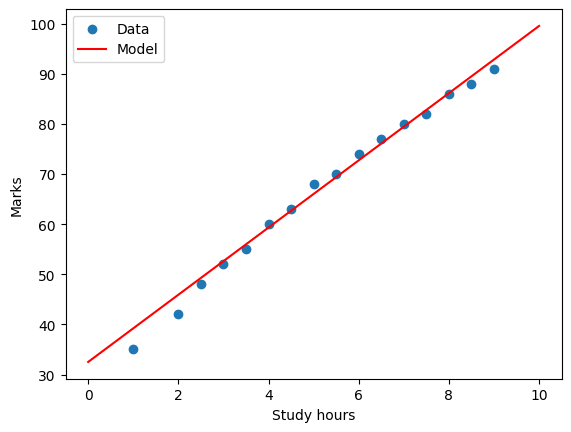

In [6]:

import numpy as np     # Library
import pandas as pd    # Change Data into DataFrame
import matplotlib.pyplot as plt  #For making Graph
from sklearn.linear_model import LinearRegression  # Regression( For straight Line)
from sklearn.model_selection import train_test_split # split in data for training and testing
from sklearn.metrics import r2_score, mean_absolute_error  # Two ways to find accuracy of Data

# 1. Data (hours per day, marks out of 100)
data = {
    "hours": [1, 2, 2.5, 3, 3.5, 4, 4.5, 5, 5.5, 6, 6.5, 7, 7.5, 8, 8.5, 9],
    "marks": [35, 42, 48, 52, 55, 60, 63, 68, 70, 74, 77, 80, 82, 86, 88, 91],
}
df = pd.DataFrame(data)
print(df.describe())  # Descriptive statistic

# 2. Correlation (statistics wala hissa)
print("\nCorrelation:", df["hours"].corr(df["marks"]))  # Pearson correlation

# 3. Train/test split
X = df[["hours"]]  #2D table
y = df["marks"]    #1D table
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, random_state=42
)

# 4. Model train karo
model = LinearRegression()
model.fit(X_train, y_train)
print("\nSlope:", model.coef_[0])
print("Intercept:", model.intercept_)

# 5. Evaluation
pred = model.predict(X_test)
print("R2 score:", r2_score(y_test, pred))   # Data Variation
print("Mean absolute error:", mean_absolute_error(y_test, pred))  #Average difference

# 6. New Prediction
hours = 6
new = pd.DataFrame({"hours": [hours]})
print(f"\n{hours} hours study par predicted marks:", model.predict(new)[0])

# 7. Graph
plt.scatter(X, y, label="Data") #RED DOTS
line_x = pd.DataFrame({"hours": np.linspace(0, 10, 50)})
plt.plot(line_x["hours"], model.predict(line_x), color="red", label="Model")
plt.xlabel("Study hours")
plt.ylabel("Marks")
plt.legend()
plt.savefig("marks_predictor.png") # For saving graph